<a href="https://colab.research.google.com/github/Albertoromero-01/Modelado-Y-Simulacion-De-Sistemas-Mecatronicos/blob/main/ACTIVIDADES/AF7_Producto_Integrador_de_aprendizaje.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**AF7: PRODUCTO INTEGRADOR DE APRENDIZAJE (PIA).**

In [10]:
# ACTIVIDAD FUNDAMENTAL 7: PRODUCTO INTEGRADOR DE APRENDIZAJE (PIA).
# Nombre - Matrícula:
# José Alberto Romero Francisco-2000506
# Daniel Alessandro Campa Torres-2095970
# Brian Fabian Beyer Lopez-2096622
# Angel Sebastian Mendoza-Bolaños 2103541
# Hector Eduardo Nava Escobedo-2177703
# Andre Nicolas Almonte Galvan-2177929

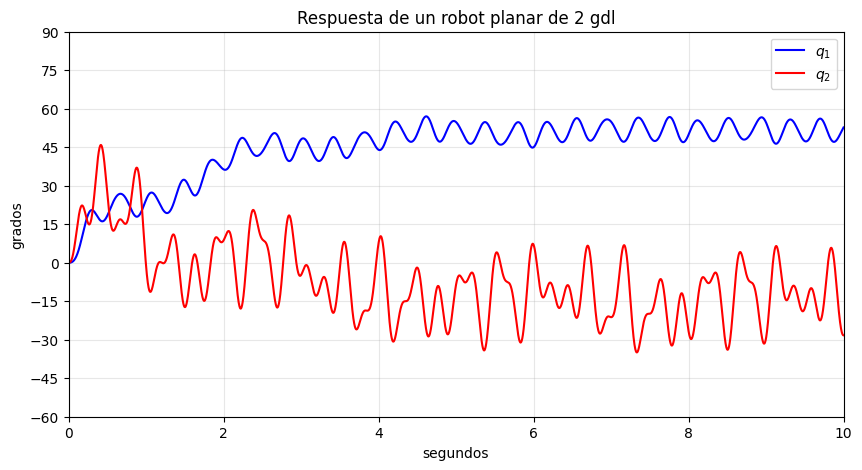

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# ---------- Modelo dinámico del robot planar de 2 gdl (Código 5.5) ----------
def robot2gdl(t, x):
    q  = np.array([x[0], x[1]])      # posiciones articulares
    qp = np.array([x[2], x[3]])      # velocidades articulares

    # Matriz de inercia
    M = np.array([
        [3.117 + 0.2*np.cos(q[1]), 0.108 + 0.1*np.cos(q[1])],
        [0.108 + 0.1*np.cos(q[1]), 0.108]
    ])

    # Matriz de fuerzas centrípetas y de Coriolis
    C = np.array([
        [-0.2*np.sin(q[1])*qp[1], -0.1*np.sin(q[1])*qp[1]],
        [ 0.1*np.sin(q[1])*qp[0],  0.0]
    ])

    # Vector de pares gravitacionales
    g = np.array([
        39.3*np.sin(q[0]) + 1.95*np.sin(q[0] + q[1]),
        1.95*np.sin(q[0] + q[1])
    ])

    # Vector de fricción viscosa + Coulomb
    fr = np.array([
        1.86*qp[0] + 1.93*np.sign(qp[0]),
        0.16*qp[1] + 0.30*np.sign(qp[1])
    ])

    # Pares aplicados por los motores
    tau = np.array([
        (1 - np.exp(-0.8*t))*32.0 + 56*np.sin(16*t + 0.1) + 12*np.sin(20*t + 0.15),
        (1 - np.exp(-1.8*t))*1.2  +  8*np.sin(26*t + 0.08) +  2*np.sin(12*t + 0.34)
    ])

    # Aceleración articular: q'' = M^-1 (tau - C qp - g - fr)
    q2p = np.linalg.solve(M, tau - C @ qp - g - fr)

    return [qp[0], qp[1], q2p[0], q2p[1]]

# ---------- Parámetros de simulación (Código 5.4) ----------
ti = 0.0
h  = 0.0025
tf = 10.0
ts = np.arange(ti, tf + h, h)
x0 = [0.0, 0.0, 0.0, 0.0]

sol = solve_ivp(robot2gdl, [ti, tf], x0, method='RK45', t_eval=ts,
                rtol=1e-3, atol=1e-6, max_step=h)

t = sol.t
q1 = np.degrees(sol.y[0])
q2 = np.degrees(sol.y[1])

# ---------- Gráfica ----------
plt.figure(figsize=(10, 5))
plt.plot(t, q1, 'b', label='$q_1$')
plt.plot(t, q2, 'r', label='$q_2$')
plt.xlabel('segundos')
plt.ylabel('grados')
plt.title('Respuesta de un robot planar de 2 gdl')
plt.yticks(np.arange(-60, 100, 15))
plt.xlim(0, 10)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

### **Conclusión y Referencias**

#### **Conclusión**
La simulación implementada del **robot planar de 2 grados de libertad (gdl)** permite analizar el comportamiento dinámico transitorio y estacionario de un sistema robótico multivariable altamente acoplado y no lineal bajo la acción de un par de excitación externo variable en el tiempo.

A través de las gráficas de respuesta de las articulaciones ($q_1$ y $q_2$), se observan los siguientes fenómenos dinámicos clave:
1. **Efectos No Lineales y de Acoplamiento:** La respuesta transitoria inicial muestra una interacción notable entre ambas articulaciones. El movimiento de una de ellas induce fuerzas de inercia, centrípetas y de Coriolis sobre la otra.
2. **Fricción y Amortiguamiento:** La presencia de fricción viscosa y de Coulomb actúa amortiguando las oscilaciones de alta frecuencia, estabilizando el comportamiento general del robot en torno a una trayectoria oscilatoria forzada.
3. **Respuesta Forzada (Excitación Armónica):** Dado que los pares aplicados por los motores (fuerzas de entrada $\tau$) contienen componentes sinusoidales de frecuencias altas (de hasta $26\text{ rad/s}$), el robot no alcanza un punto de equilibrio estático, sino que describe un régimen permanente de oscilaciones periódicas acopladas.

Este análisis es fundamental para el posterior diseño de controladores de movimiento (como el control por par computado o PID robusto) que busquen compensar de manera exacta estas dinámicas no lineales.

---

#### **Referencias Bibliográficas**
1. **Spong, M. W., Hutchinson, S., & Vidyasagar, M.** (2020). *Robot Modeling and Control* (2nd ed.). Wiley.
2. **Craig, J. J.** (2005). *Introduction to Robotics: Mechanics and Control* (3rd ed.). Pearson/Prentice Hall.
3. **Kelly, R., Santibáñez, V., & Loría, A.** (2005). *Control de Movimiento de Robots Manipuladores*. Pearson Educación.
4. **Siciliano, B., Sciavicco, L., Villani, L., & Oriolo, G.** (2009). *Robotics: Modelling, Planning and Control*. Springer Science & Business Media.